# Download the spectra for each source

*** currently this notebook only downloads SDSS spectra, which is probably enough for this source. If we use the southern hemisphere LSQ candidates,
we can add GAMA

In [65]:
%matplotlib inline
import sys, os, glob, copy, re, shutil

from astropy.io import fits, ascii
import numpy as np
import matplotlib.pyplot as plt
from astropy import units as u
import astropy.constants as const
from astropy.coordinates import SkyCoord, concatenate
from astropy import table
from astropy.convolution import Box1DKernel, convolve
from astroquery.sdss import SDSS
from astropy.wcs import WCS

from astropy.io import fits

from astropy.table import QTable, Table, Column

import scienceplots

plt.style.use(['bright', 'science', 'no-latex','notebook'])

read tables 

**This notebook does not change these tables**

In [66]:
data_agn_updated = ascii.read('local_agn_updated.txt')
data_agn = ascii.read('local_agn.txt')

ra, dec = data_agn_updated['ra'], data_agn_updated['dec']
data_coords = SkyCoord(ra, dec, unit=[u.deg, u.deg])

prepare a table for downloading flag (?) 

In [67]:
data_agn_download = copy.deepcopy(data_agn_updated)

In [68]:
data_agn_download

ra,dec,z,logMs,ID,z_simb,r_z_simb,z_best
float64,float64,float64,float64,int64,float64,str19,float64
0.47615,0.125693,0.1395,7690000000.0,0,0.13954,2015ApJS..219...12A,0.13954
2.36003,0.325606,0.1138,2940000000.0,1,-1.0,--,0.1138
4.27033,-0.493348,0.0672,9350000000.0,2,0.06716,2012ApJS..203...21A,0.06716
6.96605,0.794382,0.0821,6260000000.0,3,0.08207,2012ApJS..203...21A,0.08207
8.39416,0.048925,0.1067,8030000000.0,4,0.10677,2009ApJS..182..543A,0.10677
8.15918,-1.009817,0.0917,9150000000.0,5,0.09172,2012ApJS..203...21A,0.09172
11.38946,-0.969121,0.1376,7400000000.0,6,0.1376,2012ApJS..203...21A,0.1376
11.51401,0.636591,0.1246,3810000000.0,7,-1.0,--,0.1246
14.01926,0.59255,0.056,7760000000.0,8,0.056,2023ApJS..267...17L,0.056


### Dataset overview

The following sources have a publically available spectra

* GAMA
* DESI
* SDSS

In general, the process for downloading the spectra is as follows:
1) Download catalogue
2) Create table with file name(or any other sort of identifier), RA, and DEC
3) Match the coordinates of the catalogue AGN with the 706 AGN in our parent sample of optically-variable AGN
4) Print out the file name and (OUR OWN RUNNING) ID of the matched AGN
5) Download spectra

## SDSS 

No catalogue needed, SDSS does its own query

Download the spectra and label the table at once: 

In [69]:
idx_data = []
sdss_targets = []

for i in range(len(data_agn_updated)): 
    pos = data_coords[i]
    xid = SDSS.query_region(pos, radius='1.5 arcsec', spectro=True)
    
    if xid is None: 
        continue
    
    print(i+1)
    print(xid['objid'])
    if len(xid)>=2: 
        print(i+1, 'has multiple spectra: ')
        xid.pprint_all()
    # else: 
    #     print(i+1, 'has a spectrum')
    sdss_targets.append(xid)
    idx_data.append(i)

len(idx_data)


1
       objid       
-------------------
1237663784197619854
1237663784197619854
1 has multiple spectra: 
        ra               dec               objid        run  rerun camcol field     z     plate  mjd  fiberID     specobjid      run2d
----------------- ----------------- ------------------- ---- ----- ------ ----- --------- ----- ----- ------- ------------------ -----
0.476157431220672 0.125678417803714 1237663784197619854 4263   301      4   119 0.1395429   387 51791     160 435767274461227008    26
0.476157431220672 0.125678417803714 1237663784197619854 4263   301      4   119 0.1395898   685 52203     493 771376987955554304    26
2
       objid       
-------------------
1237663543697014931
3
       objid       
-------------------
1237657190370181289
1237657190370181289
3 has multiple spectra: 
       ra              dec                objid        run  rerun camcol field     z      plate  mjd  fiberID     specobjid      run2d
--------------- ------------------ --------------

/Users/colinburke/miniconda3/lib/python3.11/site-packages/astroquery/sdss/core.py:874: VisibleDeprecationWarning: Reading unicode strings without specifying the encoding argument is deprecated. Set the encoding, use None for the system default.
  arr = np.atleast_1d(np.genfromtxt(io.BytesIO(response.content),


243

fill in the table

In [70]:
data_agn_download['spec_sdss'] = False
data_agn_download['z_sdss'] = -1. 
for i in range(len(idx_data)): 
    data_agn_download['spec_sdss'][idx_data[i]] = True
    data_agn_download['z_sdss'][idx_data[i]] = sdss_targets[i]['z'][-1]

download the spectra

In [71]:
sdss_dir = 'spec/SDSS'
for i in range(len(idx_data)): 
    sp = SDSS.get_spectra(matches=sdss_targets[i])
    sp[-1].writeto(os.path.join(sdss_dir, 'sdss_'+str(data_agn_download[idx_data][i]['ID'])+'.fits'), overwrite=True) # if more than 1, then the last one (-1) is probably the newest

## Summary

Check how many spectra each target has: 

In [72]:
data_agn_download.pprint_all()

     ra        dec        z       logMs      ID   z_simb         r_z_simb        z_best   spec_sdss    z_sdss  
----------- ---------- ------- ------------ --- ---------- ------------------- ---------- --------- -----------
    0.47615   0.125693  0.1395 7690000000.0   0    0.13954 2015ApJS..219...12A    0.13954      True   0.1395898
    2.36003   0.325606  0.1138 2940000000.0   1       -1.0                  --     0.1138      True   0.1137971
    4.27033  -0.493348  0.0672 9350000000.0   2    0.06716 2012ApJS..203...21A    0.06716      True  0.06716701
    6.96605   0.794382  0.0821 6260000000.0   3    0.08207 2012ApJS..203...21A    0.08207      True   0.0820729
    8.39416   0.048925  0.1067 8030000000.0   4    0.10677 2009ApJS..182..543A    0.10677      True   0.1067182
    8.15918  -1.009817  0.0917 9150000000.0   5    0.09172 2012ApJS..203...21A    0.09172      True  0.09172478
   11.38946  -0.969121  0.1376 7400000000.0   6     0.1376 2012ApJS..203...21A     0.1376      True   0.

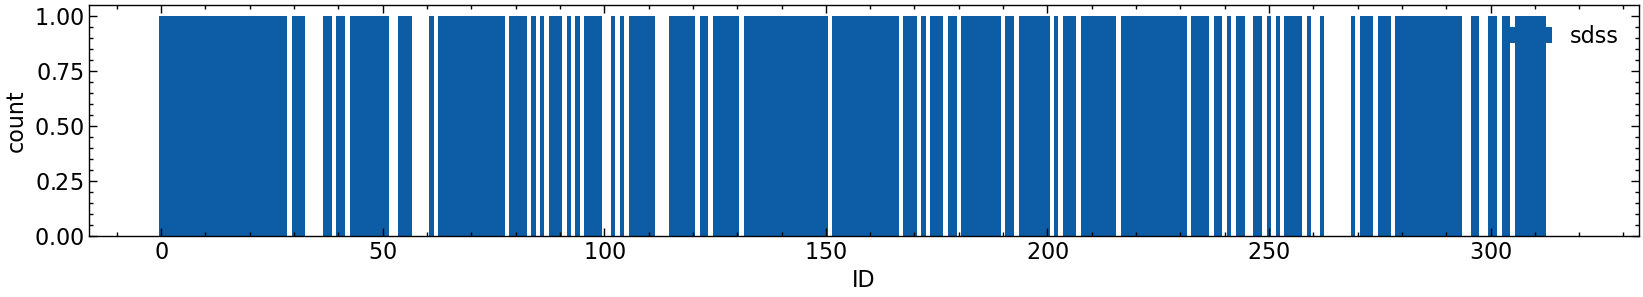

In [73]:
plt.figure(figsize=[20, 3])
spectra_counts = np.zeros(len(data_agn_download))
for flag in ['spec_sdss']: 
    plt.bar(data_agn_download['ID'], data_agn_download[flag], width=1, bottom=spectra_counts, label=flag[5:])
    spectra_counts += data_agn_download[flag]
plt.xlabel('ID')
plt.ylabel('count')
plt.legend(ncol=4)
#plt.xlim(-3, 495)
#plt.ylim(0, 10)

Visually check if most of the targets having more than 2 spectra is consistent

### Vizualize spectra

In [74]:
line_cen = np.array( [6564.60,            4862.68,    2797,    1908, 1549.06, 1215.67])
line_name = np.array([r'H$\alpha$+[NII]', r'H$\beta$','MgII'  , 'CIII]', 'CIV',   r'Ly$\alpha$'])

wmin = 3000
wmax = 11000

    
def visualize(ID, plot_template=True):

    ra = data_agn_download['ra'][data_agn_download['ID']==ID].data[0]
    dec = data_agn_download['dec'][data_agn_download['ID']==ID].data[0]

    fig, ax = plt.subplots(1,1, figsize=(8,4.5))

    source_survey = None
    
    ylim = -0.5

    z_sdss = -1
    z_desi = -1

    z = data_agn_download['z_best'][ID-1]

    # GAMA
    if os.path.isfile('spec/GAMA/GAMA_%d.fit'%ID): 

        print(f'{ID} has a GAMA spectra, z = {z}')

        hdul_gama = fits.open('spec/GAMA/GAMA_%d.fit'%ID)
        header = hdul_gama[0].header
        data = hdul_gama[0].data
        flux = data[0]
        flux_err = data[1]
        mask = np.isfinite(flux) & np.isfinite(flux_err)

        w = WCS(header, naxis=1, relax=False, fix=False)

        wave = w.wcs_pix2world(np.arange(len(flux)), 0)[0]

        ax.plot(wave[mask], flux[mask], 
                label=f'GAMA (z={z})', color='coral', linewidth=1, alpha=0.5)
        
        ylim = np.max([ylim, np.nanmax(flux[mask])])

        source_survey = 'GAMA'
                
    # SDSS
    
    if os.path.isfile('spec/SDSS/sdss_%d.fits'%ID): 
        
        z_sdss = data_agn_download['z_best'][ID-1]

        hdul_sdss= fits.open('spec/SDSS/sdss_%d.fits'%ID)
        mask_sdss = np.isfinite(hdul_sdss[1].data['flux'])
        flux_sdss = convolve(hdul_sdss[1].data['flux'][mask_sdss], Box1DKernel(width=10))
        ax.plot(10**hdul_sdss[1].data['loglam'][mask_sdss], flux_sdss,
                 label=f'SDSS (z={z_sdss})', color='bisque', linewidth=1);
        
        mask = np.isfinite(flux_sdss)
        #ylim = np.max([ylim, np.nanmax(flux_sdss[mask])])

        source_survey = 'SDSS'
        

    # DESI
    if os.path.isfile('spec/desi/desi_%d.txt'%ID): 

        z_desi = data_agn_download['z_desi'][ID-1]
        
        data_spec = ascii.read('spec/desi/desi_%d.txt'%ID)
        flux_desi = convolve(data_spec['col2'], Box1DKernel(width=10))
        ax.plot(data_spec['col1'], flux_desi,
                 label=f'DESI (z={z_desi})', color='g', linewidth=1);
        
        mask = np.isfinite(flux_desi)
        ylim = np.max([ylim, np.nanmax(flux_desi[mask])])

        source_survey = 'DESI'


    ax.set_xlim(wmin, wmax)
    ax.set_ylim(0.0, 1.2*ylim)        

    plt.title(f'ID: {ID}   Survey: {source_survey}')



    # TEMPLATES
    # Template data
    hdutemp = SDSS.get_spectral_template('qso')[0]
    datatemp = hdutemp[0].data
    headertemp = hdutemp[0].header
    start, stop, num = headertemp['COEFF0'], headertemp['COEFF0']+headertemp['COEFF1']*datatemp[1].size, datatemp[1].size
    # Line position
    if plot_template: 
        axis_to_data = ax.transAxes + ax.transData.inverted()
        points_data = axis_to_data.transform((0, 0.92))
        
        for z in [z_sdss, z_desi]:
            # Template
            if z > 0:
                ax.plot(np.logspace(start, stop, num)*(1 + z), datatemp[1]/np.max(datatemp[1])*ylim, #np.nanmax(flux_deimos), 
                        label=f'template (z = {z})', linewidth=1, alpha=0.75, color='k', linestyle='-')

                for ll in range(len(line_cen)):
                    if line_cen[ll]*(1 + z) > wmin and line_cen[ll]*(1 + z) < wmax:
                        ax.axvline(line_cen[ll]*(1 + z), 0, 5, linewidth=1, color='k', alpha=0.5)
                        ax.text(line_cen[ll]*(1 + z) + 7, points_data[1], line_name[ll], rotation=90, fontsize=10, va='top')
                        
    
    ax.legend(fontsize=12, loc=2);
    ax.set_ylabel(r'$f_{\lambda}$ (erg s$^{-1}$ cm$^{-2}$ $\AA^{-1})$')
    ax.set_xlabel(r'Wavelength ($\AA$)')
    
    return ax

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


<Axes: title={'center': 'ID: 60   Survey: None'}, xlabel='Wavelength ($\\AA$)', ylabel='$f_{\\lambda}$ (erg s$^{-1}$ cm$^{-2}$ $\\AA^{-1})$'>

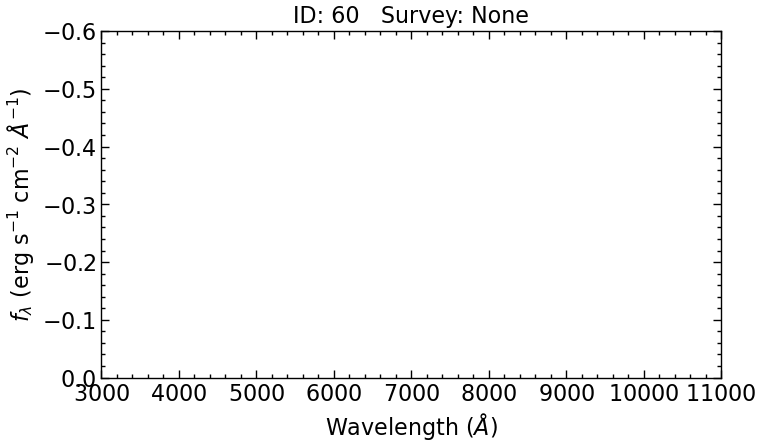

In [75]:
visualize(60)